# Lesson 09b: Implementation of Allegro in e3nn

**What you will learn**

- How to implement the two-body scalar embedding (Bessel RBF $\times$ envelope
  $\times$ species one-hots), the initial equivariant features, and the Allegro
  layer (environment embedding $\to$ channel-wise tensor product $\to$ latent
  MLP $\to$ linear mixing).
- How to assemble pair-wise energies $E_{ij}$ into $E_\text{system}$ and get
  forces from autograd.
- How to verify energy invariance and force covariance under rotations,
  inversion, and translations in `float64` and check the smoothness of the model
  predictions at the cutoff.
- How to train Allegro (in `float32` on a GPU) on **rMD17 aspirin** dataset
  under the protocol of Lesson 08c. We plot and analyze the learning curves and
  the force parity plot.
- How to time a forward pass vs. atom count to connect strict locality to linear
  scaling.

**Prerequisites:**

- Lessons [03a](03a_tensor_products_theory.ipynb) and
  [03b](03b_tensor_products_e3nn.ipynb),
- Lessons [05a](05a_atomistic_graphs.ipynb) and
  [05b](05b_radial_basis_and_cutoffs.ipynb),
- Lessons [08a](08a_nequip_theory.ipynb), [08b](08b_nequip_implementation.ipynb)
  and [08c](08c_nequip_training.ipynb), and
- Lesson [09a](09a_allegro_theory.ipynb).

In [1]:
import sys; sys.path.insert(0, "..")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from e3nn import o3

from course_utils.data import load_rmd17, radius_graph
from course_utils.equivariance import model_equivariance_error
from course_utils.plotting import plot_training_curves

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, "| device:", device)

2.7.1+cu126 | device: cuda


## Simplifications in Allegro's Implementation

In this lesson, we build a simple and small version of the **Allegro** model,
block by block, following the equations of Lesson 09a. Then, we verify its
symmetries and train it simultanelously on energies and forces. 

**Our model is educational** and faithful to the original implementation but we
have changed it to make it easier to understand and implement here. Explicitly:

| Paper | Here | Why |
|---|---|---|
| Per-species(-pair) $\sigma_{Z}, \mu_{Z}$, and $\sigma_{Z_iZ_j}$ | One global learnable scale $\sigma$ and shift $\mu$ | The species one-hots are kept (aspirin is H/C/O) but per-species output scales are a refinement we skip |
| All symmetrically valid tensor product paths (hyperparameter) | The output irreps are restricted to those of $\vec{Y}$: $0e, 1o, 2e$ | Fewer paths, same structure, and still exactly equivariant |
| Normalized residual update in the scalar latent space route | Plain residual $x^{ij,L} = x^{ij,L-1} + (\text{new})\cdot u(r_{ij})$ | Same idea but simpler |
| Large widths, $\ell_\text{max}=3$, deep latent MLPs | Latent width of 32, $C=8$ channels, $\ell_\text{max}=2$, 2 layers | Allows minutes-long training for the course |
| $E_{ij} = \mathrm{MLP}_\text{output}(x^{ij})$ | Additionally multiplied by the envelope, $u(r_{ij})$ | Guarantees $E_{ij}\to 0$ smoothly at the cutoff even with biased MLPs |
| Environment weights $w^{ik,L}$ | Additionally multiplied by the envelope, $u(r_{ik})$ | Neighbors must enter the sum smoothly as they cross the cutoff |

The last two rows are the only places we add something: without those envelope
factors, an MLP bias would make a neighbor appear/disappear discontinuously at
$r_c$ (the original Allegro achieves the same smoothness through its
normalization and envelope placement).

## Radial basis and cutoff envelope

As in Lesson 05b, distances are expanded in $N_\text{basis}$ Bessel functions,

$$B_n(r) = \sqrt{\frac{2}{r_c}}\, \frac{\sin(n \pi r / r_c)}{r}, \qquad n = 1, \dots, N_\text{basis},$$

and smoothness at the cutoff is enforced by the polynomial envelope introduced
with DimeNet and used by NequIP and Allegro, with $x = r/r_c$ and exponent $p$:

$$u(r) = 1 - \tfrac{(p+1)(p+2)}{2} x^{p} + p(p+2)\, x^{p+1} - \tfrac{p(p+1)}{2}\, x^{p+2}, \qquad u \equiv 0 \text{ for } r \ge r_c.$$

Note that $u$ has $p-1$ vanishing derivatives at $r = r_c$. Thus, basis
functions multiplied by it fade out smoothly. [Lesson
05b](05b_radial_basis_and_cutoffs.ipynb) plots both $B_n(r)$ and the product
$B_n(r)\,u(r)$ and shows numerically what a hard cutoff does to forces.
Therefore, we only restate the definitions here and move on.

In [2]:
# Lesson 08c's aspirin cutoff
r_cut = 5.0

class BesselBasis(nn.Module):
    """Bessel basis functions B_n(r)"""
    
    def __init__(self, r_cut, n_basis=8):
        super().__init__()
        self.r_cut, self.prefactor = r_cut, (2.0 / r_cut) ** 0.5
        self.register_buffer("n_pi", torch.arange(1, n_basis + 1) * torch.pi)

    def forward(self, r):
        # (E,) -> (E, n_basis)
        r = r.unsqueeze(-1)
        return self.prefactor * torch.sin(self.n_pi * r / self.r_cut) / r


def poly_envelope(r, r_cut, p=6):
    """Smooth cutoff u(r): u(0)=1, u and its first p-1 derivatives vanish at r_cut."""
    
    # The polynomial is defined in terms of x = r/r_cut, which is clamped to 1.0
    x = (r / r_cut).clamp(max=1.0)
    
    # The polynomial is constructed to satisfy the boundary conditions:
    # u(0) = 1, u(r_cut) = 0, and the first p-1 derivatives vanish at r_cut.
    u = (1.0 - (p + 1) * (p + 2) / 2 * x**p + p * (p + 2) * x**(p + 1)
         - p * (p + 1) / 2 * x**(p + 2))
    
    # The polynomial is multiplied by the indicator function (r < r_cut) to
    # ensure that u(r) = 0 for r >= r_cut.
    return u * (r < r_cut)


def scalar_mlp(dims):
    """Plain MLP with SiLU hidden activations which is only ever applied to invariants!"""
    
    layers = []
    for a, b in zip(dims[:-1], dims[1:]):
        layers += [nn.Linear(a, b), nn.SiLU()]
    
    # No activation on the output
    return nn.Sequential(*layers[:-1])

## Two-body embedding and helper for weighted spherical harmonics
 
Allegro embeds each atomic pair using its distance **and the identities of its
two atoms**:

$$x^{ij, L=0} = \mathrm{MLP}_\text{two-body}\big( B(r_{ij}) \Vert \mathbf{1}_{Z_i} \Vert \mathbf{1}_{Z_j} \big) \cdot u(r_{ij})$$

where $\mathbf{1}_Z$ is the one-hot encoding of the atomic species and $\Vert$
denotes concatenation. Aspirin has three species (H, C, O) and the one-hot
encodings allow the embedding to distinguish between different atomic pairs at
the same distance. For example, the embeddings of one-hot encodings of C–H pair
is different from that of a C–O pair at the same distance. As one-hot encodings
are invariant scalars, concatenating them cannot disturb the equivariance in the
model.

The initial features of the tensor latent space route are the weighted spherical
harmonics of the pair directions:

$$V^{ij,L=0}_{n,\ell,p} = w^{ij,L=0}_{n,\ell,p}\, \vec{Y}^{\,ij}_{\ell,p},$$

where

$$ w^{ij,L=0} = \mathrm{Linear}\big(x^{ij,L=0}\big).$$

The weighting operation (multiplying each irrep of $\vec{Y}$ by a per-channel
scalar) appears twice in Allegro: here, and again inside the environment
embedding of the layer. Therefore, we factor it out in a reusable function,
`weighted_sh(w, Y, irreps_Y)` below. This function takes `w` of shape 
`(E, c, n_irreps)`, which consists of one scalar per edge, channel and irrep,
together with `Y` of shape `(E, Y.dim)`, and returns `(E, c * Y.dim)`, laid out as the e3nn irreps 
`cx0e + cx1o + cx2e`, where $c$ is the number of channels. Note that 
multiplying an irrep by an invariant scalar, which commutes with $D^{(\ell)}(g)$,
keeps the results equivariant.

In [ ]:
def weighted_sh(w, Y, irreps_Y):
    """w: (E, c, n_irreps) scalar weights;  Y: (E, Y.dim) spherical harmonics.
    Returns (E, c * Y.dim) with irreps [c x ir for ir in irreps_Y]"""
    
    # Create a list to hold the weighted spherical harmonics blocks and
    # initialize an index counter
    blocks, idx = [], 0
    
    # Loop over the irreps of Y and their corresponding weights
    for m, (_, ir) in enumerate(irreps_Y):
        
        # Compute the weighted spherical harmonics block for the current irrep
        # (E, c, 2l+1)
        blk = w[:, :, m : m + 1] * Y[:, None, idx : idx + ir.dim]
        
        # Reshape the block to (E, c * (2l+1)) and append it to the list of
        # blocks
        blocks.append(blk.reshape(len(Y), blk.shape[1] * blk.shape[2]))
        
        # Update the index counter
        idx += ir.dim
    
    # Concatenate all the blocks along the last dimension to form the final
    # output
    return torch.cat(blocks, dim=-1)


The $\mathrm{MLP}_\text{two-body}$ (and the $\mathrm{Linear}$ layer) that
produces the weights, $w^{ij,L=0}$, are assembled directly inside `AllegroModel`
later in the text when we implement the full Allegro model.

## Channel-wise tensor product

Here, we need to implement a layer that couples the tensor latent space track
with its environment through a tensor product that is **weight-free and
channel-wise**: channel $c$ of the first input only ever meets channel $c$ of
the second one (e3nn's `"uuu"` instruction mode). We also keep only those output
irreps that $V$ already carries (i.e., $0e$, $1o$, $2e$) while discarding any
path the selection rule permits but this architecture never uses.

The `channelwise_tp(irreps_V, irreps_env, allowed)` function below enumerates
the surviving paths and returns the configured `o3.TensorProduct`. The Allegro
layer in the next section calls it exactly once, in its constructor.

In [4]:
def channelwise_tp(irreps_V, irreps_env, allowed):
    """Weight-free channel-wise ("uuu") tensor product with all allowed paths
    built in Lesson 09a."""
    
    # Convert the allowed irreps to a set for faster lookup
    allowed = {o3.Irrep(ir) for ir in allowed}
    
    # Initialize the output irreps and instructions for the tensor product
    irreps_out, instructions = [], []
    for i1, (mul, ir1) in enumerate(irreps_V):
        for i2, (_, ir2) in enumerate(irreps_env):
            
            # Selection rule
            for ir_out in ir1 * ir2:
                
                # Check if the output irrep is in the allowed set
                if ir_out in allowed:
                    
                    # Add the instruction for this allowed tensor product path
                    instructions.append((i1, i2, len(irreps_out), "uuu", False))
                    
                    # Record the output irrep for this tensor product path
                    irreps_out.append((mul, ir_out))
    
    # Return the tensor product object with the computed output irreps and
    # instructions
    return o3.TensorProduct(irreps_V, irreps_env, o3.Irreps(irreps_out), instructions,
                            internal_weights=False, shared_weights=False)


## The Allegro layer

The Allegro layer implements the four components from Lesson 09a:

1. **Environment weights**: $w^{ik,L} = \mathrm{Linear}(x^{ik,L-1}) \cdot
   u(r_{ik})$. Our extra envelope factor, $u(r_{ik})$ makes extrnal atoms enter
   the atomic neighborhood smoothly.

2. **Embedded environment + tensor product**: $\;V^{ij,L}_\text{paths} =
   V^{ij,L-1} \otimes \Big(\sum_{k \in \mathcal{N}(i)} w^{ik,L}
   \vec{Y}^{ik}\Big)$. The sum over $k$ is a scatter-add over all edges with
   center $i$, then divided by $\sqrt{\langle |\mathcal{N}(i)| \rangle}$.

3. **Latent MLP + residual**: the $0e$ outputs of the tensor product re-enter
   the scalar latent space track.
   
4. **Linear mixing**: The `o3.Linear` layer recombines all paths carrying the same irrep
   into $c$ channels.

In [ ]:
class AllegroLayer(nn.Module):
    """Allegro layer as described in the paper, with some simplifications for
    the course."""
    
    def __init__(self, irreps_V, irreps_Y, latent_dim, avg_n_neighbors):
        super().__init__()
        
        # Convert the input irreps to e3nn Irreps objects and store them
        irreps_V, self.irreps_Y = o3.Irreps(irreps_V), o3.Irreps(irreps_Y)
        
        # Store the number of channels and the average number of neighbors for normalization
        self.C, self.avg_n = irreps_V[0].mul, avg_n_neighbors
        
        # (1) Environment embedding weights
        self.env_embed = nn.Linear(latent_dim, self.C * len(self.irreps_Y))
        irreps_env = o3.Irreps([(self.C, ir) for _, ir in self.irreps_Y])
        
        # (2) Channel-wise tensor product
        self.tp = channelwise_tp(irreps_V, irreps_env, [ir for _, ir in irreps_V])
        
        # Scalar slices for locating the 0e outputs of the tensor product
        self.scalar_slices, idx = [], 0
        for mul, ir in self.tp.irreps_out:
            if ir == o3.Irrep("0e"):
                self.scalar_slices.append((idx, idx + mul * ir.dim))
            idx += mul * ir.dim
        n_scalars = sum(b - a for a, b in self.scalar_slices)
        
        # (3) Latent MLP
        self.latent_mlp = scalar_mlp([latent_dim + n_scalars, latent_dim, latent_dim])
        
        # (4) Linear mixing of paths
        self.linear = o3.Linear(self.tp.irreps_out, irreps_V)

    def forward(self, x, V, Y, u, edge_center, n_atoms):
        # w^{ik,L}: (E, C, n_irreps_Y), smooth at the cutoff
        w = self.env_embed(x).reshape(len(x), self.C, len(self.irreps_Y)) * u[:, None, None]
        
        # Embedded environment: scatter-add over edges with center i; inner sum
        env_edge = weighted_sh(w, Y, self.irreps_Y)
        env = torch.zeros(n_atoms, env_edge.shape[-1], device=Y.device, dtype=Y.dtype)
        env.index_add_(0, edge_center, env_edge)
        
        # Internal normalization
        env = env / self.avg_n ** 0.5
        
        # Tensor product with the environment
        tp_out = self.tp(V, env[edge_center])
        
        # Extract scalar outputs from the tensor product and update the latent features
        scal = torch.cat([tp_out[:, a:b] for a, b in self.scalar_slices], dim=-1)
        
        # Residual update of the latent features using the latent MLP and the scalar outputs
        x = x + self.latent_mlp(torch.cat([x, scal], dim=-1)) * u[:, None]
        
        # Linear mixing of the tensor product outputs to produce the final output
        V = self.linear(tp_out)
        return x, V

## The full model

Assembly (one global learnable scale $\sigma$ and shift $\mu$, rather than the paper's per-species pair):

$$E_{ij} = \mathrm{MLP}_\text{output}\big(x^{ij,L=N_\text{layer}}\big) \cdot u(r_{ij})$$

*Eq. (17 + envelope)*

$$E_i = \sum_{j \in \mathcal{N}(i)} E_{ij}\qquad\qquad E_\text{system} = \sum_i^N \sigma E_i + \mu$$

*Eq. (6)* *Eq. (5)*

Following the paper's target normalization (Methods, "Normalization of targets"), we initialize $\sigma$ to the root-mean-square of the training force components and subtract the training set's mean energy *per atom* from the targets (Lesson 08c's recipe), leaving $\mu$ free to absorb the remainder. Edge convention (course-wide): `edge_index[0]` = receiver/center $i$, `edge_index[1]` = sender/neighbor $j$, $\vec{r}_{ij} = \vec{r}_j - \vec{r}_i$.

In [6]:
class AllegroModel(nn.Module):
    def __init__(self, r_cut=5.0, n_basis=8, latent_dim=32, n_channels=8, l_max=2,
                 n_layers=2, n_species=1, avg_n_neighbors=4.0,
                 energy_shift=0.0, energy_scale=1.0):
        super().__init__()
        self.r_cut, self.n_species = r_cut, n_species
        self.irreps_Y = o3.Irreps.spherical_harmonics(l_max)         # 1x0e+1x1o+1x2e
        irreps_V = o3.Irreps([(n_channels, ir) for _, ir in self.irreps_Y])
        self.C = n_channels
        self.basis = BesselBasis(r_cut, n_basis)
        # Eq. (7): B(r) concatenated with the one-hots of BOTH atoms of the pair
        self.two_body_mlp = scalar_mlp([n_basis + 2 * n_species, latent_dim, latent_dim])
        self.embed0 = nn.Linear(latent_dim, n_channels * len(self.irreps_Y))  # Eq. (10)
        self.layers = nn.ModuleList(
            [AllegroLayer(irreps_V, self.irreps_Y, latent_dim, avg_n_neighbors)
             for _ in range(n_layers)])
        self.readout = scalar_mlp([latent_dim, latent_dim, 1])                # Eq. (17)
        self.shift = nn.Parameter(torch.tensor(float(energy_shift)))          # mu   (Eq. 5)
        self.scale = nn.Parameter(torch.tensor(float(energy_scale)))          # sigma(Eq. 5)

    def forward(self, pos, edge_index, species=None, batch=None, n_graphs=1):
        if batch is None:
            batch = torch.zeros(len(pos), dtype=torch.long, device=pos.device)
        if species is None:                                  # single-species fallback
            species = torch.zeros(len(pos), dtype=torch.long, device=pos.device)
        i, j = edge_index[0], edge_index[1]
        r_vec = pos[j] - pos[i]                              # r_ij = r_j - r_i
        r = r_vec.norm(dim=-1)
        u = poly_envelope(r, self.r_cut)
        Y = o3.spherical_harmonics(self.irreps_Y, r_vec, normalize=True,
                                   normalization="component")
        hot = F.one_hot(species, self.n_species).to(pos.dtype)                # 1_Z
        x = self.two_body_mlp(
            torch.cat([self.basis(r), hot[i], hot[j]], dim=-1)) * u[:, None]  # Eq. (7)
        w0 = self.embed0(x).reshape(len(x), self.C, len(self.irreps_Y))       # Eq. (10)
        V = weighted_sh(w0, Y, self.irreps_Y)                                 # Eq. (9)
        for layer in self.layers:                            # Eqs. (11)-(16), per layer
            x, V = layer(x, V, Y, u, i, len(pos))
        E_ij = self.readout(x).squeeze(-1) * u                                # Eq. (17)
        E_i = torch.zeros(len(pos), device=pos.device, dtype=pos.dtype)
        E_i.index_add_(0, i, E_ij)                                            # Eq. (6)
        E = torch.zeros(n_graphs, device=pos.device, dtype=pos.dtype)
        E.index_add_(0, batch, self.scale * E_i + self.shift)                 # Eq. (5)
        return E

In [7]:
def forces(model, pos, edge_index, species=None, batch=None, n_graphs=1,
           create_graph=False):
    """F = -dE/dr via autograd (unnumbered force equation, 09a section 2)."""
    pos = pos.requires_grad_(True)
    E = model(pos, edge_index, species, batch, n_graphs)
    (grad,) = torch.autograd.grad(E.sum(), pos, create_graph=create_graph,
                                  allow_unused=True)         # no edges -> no dependence
    grad = torch.zeros_like(pos) if grad is None else grad
    return E, -grad

# Build a float64 copy for the symmetry checks (equivariance is a property of the
# *architecture*, so an untrained model must already pass it exactly).
torch.manual_seed(0)
torch.set_default_dtype(torch.float64)     # e3nn bakes Wigner constants in at build time
model64 = AllegroModel(r_cut=r_cut, n_species=3)
torch.set_default_dtype(torch.float32)
print(f"parameters: {sum(p.numel() for p in model64.parameters()):,}")

pos_test = torch.randn(12, 3, dtype=torch.float64) * 2.0
spec_test = torch.randint(0, 3, (12,))                       # a mixed H/C/O cluster
ei_test = radius_graph(pos_test, r_cut)
E, F_test = forces(model64, pos_test.clone(), ei_test, spec_test)
print(f"test config: {ei_test.shape[1]} edges | E = {E.item():+.4f} | F shape {tuple(F_test.shape)}")

parameters: 12,171


test config: 88 edges | E = +3.5491 | F shape (12, 3)


## Verifying the symmetries (float64)

The model must satisfy, for every rotation/reflection $g \in O(3)$ and translation $\vec{t}$:

$$E(g\,\vec{r}_1 + \vec{t}, \dots) = E(\vec{r}_1, \dots) \qquad\text{(energy: invariant, a $0e$ scalar)}$$

$$\vec{F}_i(g\,\vec{r} + \vec{t}) = g\, \vec{F}_i(\vec{r}) \qquad\text{(forces: covariant, $1o$ vectors)}$$

We test with random group elements *including inversion* ($g = -R$) and random translations, in float64 so that any genuine symmetry breaking would stand out from round-off ($\sim 10^{-15}$). Note the edge list is reused unchanged — distances are E(3)-invariant, so the graph itself does not change.

In [8]:
# Energy invariance: E is a single 0e output -> D_out = 1, so lhs must equal rhs exactly
err_E = model_equivariance_error(
    lambda p, edge_index=None: model64(p, edge_index, spec_test).unsqueeze(-1),
    pos_test, irreps_out="0e", n_trials=10, parity=True, translation=True,
    edge_index=ei_test)
print(f"energy invariance:  max |E(g r + t) - E(r)| = {err_E:.3e}")
assert err_E < 1e-9

energy invariance:  max |E(g r + t) - E(r)| = 8.882e-16


In [9]:
# Force covariance under random O(3) elements (half of them improper) + translations
_, F0 = forces(model64, pos_test.clone(), ei_test, spec_test)
err_F = 0.0
for _ in range(10):
    g = o3.rand_matrix(dtype=torch.float64)
    if torch.rand(()) < 0.5:
        g = -g                                   # improper: test inversion/parity too
    t = torch.randn(3, dtype=torch.float64)
    _, F_g = forces(model64, (pos_test @ g.T + t), ei_test, spec_test)
    err_F = max(err_F, (F_g - F0 @ g.T).abs().max().item())
print(f"force covariance:   max |F(g r + t) - g F(r)| = {err_F:.3e}")
assert err_F < 1e-9

force covariance:   max |F(g r + t) - g F(r)| = 1.582e-15


## Dataset and training protocol

We train on **rMD17 aspirin** (Lesson 07c / `course_utils.data.load_rmd17`) under exactly the protocol of Lesson 08c: the official split 01, 150 training and 50 validation frames of the 21-atom molecule (H/C/O), $r_c = 5$ Å, mini-batches of 25 frames, and the training set's mean energy per atom subtracted from the targets. Holding the protocol fixed is the point — it puts Allegro's validation force MAE directly beside the 85.28 meV/Å that NequIP reached in 08c, on the same frames and the same metric.

This is a real test of the tensor track in a way LJ argon never was. Argon's energy is a sum of *pair* terms depending only on distance, so invariant features nearly suffice (that is why Lessons 07a–08b use it as a cheap shared control). Aspirin's DFT surface has bond angles, dihedrals, conjugation and an aromatic ring, so the $\ell \ge 1$ features have something to do — see Exercise 1.

**Loss** — the per-atom-normalized joint loss of the Allegro paper (Eq. (30), with $\lambda_E = \lambda_F = 1$):

$$\mathcal{L} = \frac{\lambda_E}{B} \sum_b^B \left( \frac{\hat{E}_b - E_b}{N} \right)^2 + \frac{\lambda_F}{3 B N} \sum_{i=1}^{BN} \sum_{\alpha=1}^{3} \left\| -\frac{\partial \hat{E}}{\partial r_{i,\alpha}} - F_{i,\alpha} \right\|^2$$

*Eq. (30)*

where $B$ is the batch size (structures), $N$ the atoms per structure, and $\alpha$ the Cartesian component. Each model is trained with *its own paper's* loss, so this is a comparison of two published recipes on one dataset, not a controlled single-variable ablation — Allegro weights the energy term by $1/N^2$ where NequIP's 08c loss does not. As in the paper we use Adam with a cosine-annealed learning rate; training runs in float32 on the GPU.

In [10]:
# Lesson 08c's data protocol: official rMD17 split 01, r_cut = 5 Å, per-atom mean shift
train_frames, val_frames, z_asp = load_rmd17("aspirin", n_train=150, n_val=50,
                                             cache_dir="artifacts")
species_map = {int(Z): s for s, Z in enumerate(torch.unique(z_asp).tolist())}  # {1:0, 6:1, 8:2}
species_asp = torch.tensor([species_map[int(Z)] for Z in z_asp])
N_ATOMS, N_SPECIES = len(z_asp), len(species_map)

# statistics for normalization (paper Methods: internal + target normalization)
eps_bar = float(np.mean([f["energy"] for f in train_frames])) / N_ATOMS      # mean E/atom
avg_n = float(np.mean([radius_graph(f["pos"], r_cut).shape[1] / N_ATOMS
                       for f in train_frames]))
F_scale = torch.cat([f["forces"].reshape(-1) for f in train_frames]).pow(2).mean().sqrt()

print(f"aspirin: {N_ATOMS} atoms (H/C/O) | {len(train_frames)} train / {len(val_frames)} val")
print(f"avg neighbors: {avg_n:.1f} | E/atom mean: {eps_bar:.4f} eV | F rms: {F_scale*1e3:.1f} meV/A")

aspirin: 21 atoms (H/C/O) | 150 train / 50 val
avg neighbors: 14.4 | E/atom mean: -838.9382 eV | F rms: 1273.2 meV/A


In [11]:
def prep(frames, dtype=torch.float32):
    """Precompute float32 graphs once; energies carry the per-atom mean shift."""
    return [(f["pos"].to(dtype), radius_graph(f["pos"].to(dtype), r_cut),
             torch.tensor(float(f["energy"]) - len(f["pos"]) * eps_bar, dtype=dtype),
             f["forces"].to(dtype)) for f in frames]

train_data, val_data = prep(train_frames), prep(val_frames)

def collate(items):
    """Merge frames into one block-diagonal batch graph (as torch-geometric would)."""
    pos = torch.cat([p for p, _, _, _ in items])
    eis, batch, off = [], [], 0
    for k, (p, e, _, _) in enumerate(items):
        eis.append(e + off); batch += [k] * len(p); off += len(p)
    spec = species_asp.repeat(len(items))                    # same molecule every frame
    return (pos, torch.cat(eis, dim=1), spec, torch.tensor(batch),
            torch.stack([E for _, _, E, _ in items]), torch.cat([f for _, _, _, f in items]))

val_batch = [t.to(device) for t in collate(val_data)]

def evaluate(model):
    pos, ei, spec, batch, E_ref, F_ref = val_batch
    E_hat, F_hat = forces(model, pos.clone(), ei, spec, batch, len(val_data))
    return ((E_hat - E_ref).abs().mean().item() / N_ATOMS * 1e3,   # meV / atom
            (F_hat - F_ref).abs().mean().item() * 1e3)             # meV / A

In [12]:
torch.manual_seed(0)
model = AllegroModel(r_cut=r_cut, n_species=N_SPECIES, avg_n_neighbors=avg_n,
                     energy_shift=0.0, energy_scale=float(F_scale)).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,} (float32, {device})")

# Lesson 08c's optimizer settings, so the two runs differ only in the architecture
n_epochs, batch_size = 600, 25
opt = torch.optim.Adam(model.parameters(), lr=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)

parameters: 12,171 (float32, cuda)


In [13]:
history = {"train loss": [], "val E MAE [meV/atom]": [], "val F MAE [meV/A]": []}
batches = [[train_data[k] for k in range(s, min(s + batch_size, len(train_data)))]
           for s in range(0, len(train_data), batch_size)]
t0 = time.time()
for epoch in range(n_epochs):
    losses = []
    for items in batches:
        pos, ei, spec, batch, E_ref, F_ref = [t.to(device) for t in collate(items)]
        E_hat, F_hat = forces(model, pos, ei, spec, batch, len(items), create_graph=True)
        loss = (((E_hat - E_ref) / N_ATOMS).pow(2).mean()        # Eq. (30), lambda_E = 1
                + (F_hat - F_ref).pow(2).mean())                 # Eq. (30), lambda_F = 1
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    sched.step()
    e_mae, f_mae = evaluate(model)
    history["train loss"].append(np.mean(losses))
    history["val E MAE [meV/atom]"].append(e_mae)
    history["val F MAE [meV/A]"].append(f_mae)
    if epoch % 100 == 0 or epoch == n_epochs - 1:
        print(f"epoch {epoch:3d} | loss {np.mean(losses):.3e} | "
              f"val E MAE {e_mae:7.3f} meV/atom | val F MAE {f_mae:7.2f} meV/A")
print(f"training time: {time.time() - t0:.0f} s on {device}")

epoch   0 | loss 1.970e+00 | val E MAE 251.255 meV/atom | val F MAE  930.78 meV/A


epoch 100 | loss 1.744e-02 | val E MAE   4.565 meV/atom | val F MAE  101.15 meV/A


epoch 200 | loss 9.670e-03 | val E MAE  16.360 meV/atom | val F MAE   79.12 meV/A


epoch 300 | loss 5.704e-03 | val E MAE   9.537 meV/atom | val F MAE   67.59 meV/A


epoch 400 | loss 6.076e-03 | val E MAE  15.929 meV/atom | val F MAE   74.65 meV/A


epoch 500 | loss 4.153e-03 | val E MAE   1.526 meV/atom | val F MAE   62.59 meV/A


epoch 599 | loss 3.973e-03 | val E MAE   1.481 meV/atom | val F MAE   62.14 meV/A
training time: 204 s on cuda


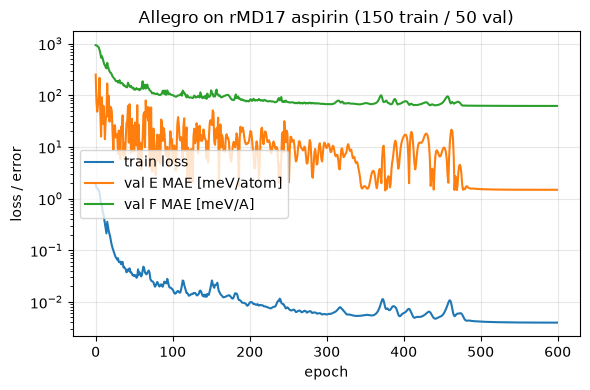

In [14]:
ax = plot_training_curves(history)
ax.set_title("Allegro on rMD17 aspirin (150 train / 50 val)")
ax.figure.tight_layout()

final validation:  E MAE = 1.481 meV/atom | F MAE = 62.14 meV/A
NequIP on the same frames (Lesson 08c): E MAE = 1.51 meV/atom | F MAE = 85.28 meV/A


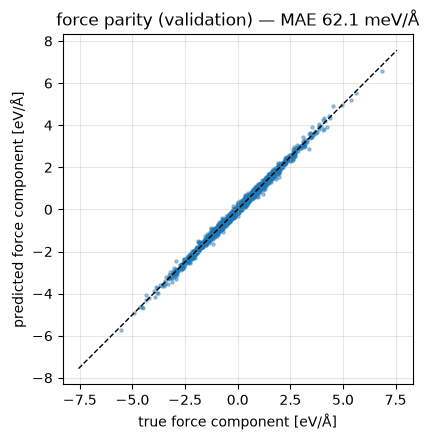

In [15]:
pos, ei, spec, batch, E_ref, F_ref = val_batch
E_hat, F_hat = forces(model, pos.clone(), ei, spec, batch, len(val_data))
e_mae, f_mae = evaluate(model)
print(f"final validation:  E MAE = {e_mae:.3f} meV/atom | F MAE = {f_mae:.2f} meV/A")
print(f"NequIP on the same frames (Lesson 08c): E MAE = 1.51 meV/atom | F MAE = 85.28 meV/A")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
F_t, F_p = F_ref.cpu().numpy().ravel(), F_hat.detach().cpu().numpy().ravel()
ax.scatter(F_t, F_p, s=5, alpha=0.4)
lim = np.abs(F_t).max() * 1.1
ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
ax.set_xlabel(r"true force component [eV/$\mathrm{\AA}$]")
ax.set_ylabel(r"predicted force component [eV/$\mathrm{\AA}$]")
ax.set_title(rf"force parity (validation) — MAE {f_mae:.1f} meV/$\mathrm{{\AA}}$")
ax.set_aspect("equal"); ax.grid(alpha=0.3)
fig.tight_layout()

## Sanity checks on the *trained* model

**Symmetries again** — training must not (and cannot) break them; in float32 the error floor is $\sim 10^{-6}$ eV from round-off, not from symmetry breaking.

**Smoothness at the cutoff** — we scan an isolated **C–C pair** through $r = r_c$. Because every pair quantity carries the envelope $u(r)$, the interaction energy and force must go to zero *smoothly*; beyond $r_c$ the model returns exactly $2\mu$ (two isolated-atom shifts). A discontinuity here would make MD unstable (Lesson 05b). We batch all scan points as independent 2-atom graphs and keep the $>r_c$ edges in the graph on purpose — their contribution must vanish identically. Note this is an *extrapolation*: the model only ever saw whole aspirin molecules, never an isolated pair, so only the behaviour at $r_c$ is the claim here, not the shape of the curve.

In [16]:
pos32 = val_data[0][0].to(device)
ei32 = val_data[0][1].to(device)
spec32 = species_asp.to(device)
E0 = model(pos32, ei32, spec32)
_, F0 = forces(model, pos32.clone(), ei32, spec32)
err_E32, err_F32 = 0.0, 0.0
for _ in range(10):
    g = o3.rand_matrix(dtype=torch.float32, device=device)
    if torch.rand(()) < 0.5:
        g = -g
    t = torch.randn(3, device=device)
    E_g = model(pos32 @ g.T + t, ei32, spec32)
    _, F_g = forces(model, (pos32 @ g.T + t), ei32, spec32)
    err_E32 = max(err_E32, (E_g - E0).abs().max().item())
    err_F32 = max(err_F32, (F_g - F0 @ g.T).abs().max().item())
print(f"trained model, float32: energy error {err_E32:.2e} eV, force error {err_F32:.2e} eV/A")
assert err_E32 < 1e-4 and err_F32 < 1e-4      # float32 round-off floor, not symmetry breaking

trained model, float32: energy error 2.50e-06 eV, force error 2.13e-05 eV/A


beyond cutoff: |E - 2 mu| = 0.00e+00 eV (exactly the shift)


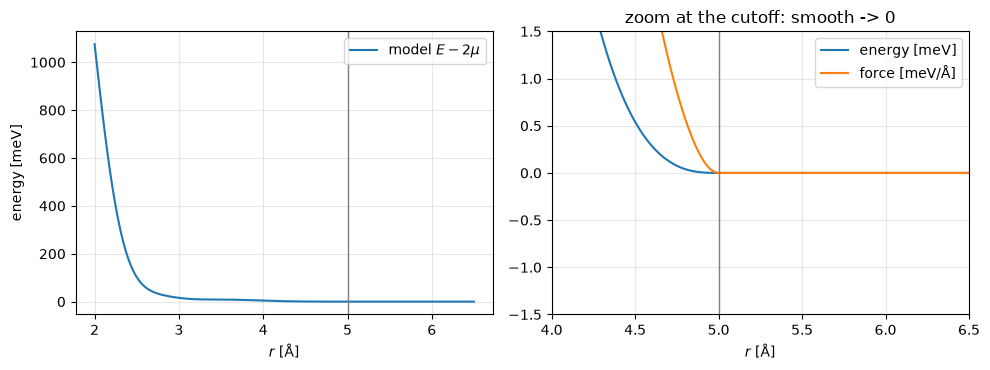

In [17]:
n_scan = 400
r_scan = torch.linspace(2.0, 6.5, n_scan, device=device)   # above the repulsive wall
pos_d = torch.zeros(2 * n_scan, 3, device=device)
pos_d[1::2, 0] = r_scan                                   # pair k: atoms 2k, 2k+1
k2 = torch.arange(n_scan, device=device) * 2
ei_d = torch.cat([torch.stack([k2, k2 + 1]), torch.stack([k2 + 1, k2])], dim=1)
batch_d = torch.arange(n_scan, device=device).repeat_interleave(2)
spec_d = torch.full((2 * n_scan,), species_map[6], device=device)   # a C-C pair

E_d, F_d = forces(model, pos_d, ei_d, spec_d, batch_d, n_scan)
E_int = (E_d - 2 * model.shift).detach().cpu()            # remove isolated-atom shifts
F_x = F_d[1::2, 0].detach().cpu()                         # force on the far atom
r_np = r_scan.cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(r_np, E_int * 1e3, label=r"model $E - 2\mu$")
axes[0].set_ylabel("energy [meV]"); axes[0].legend()
axes[1].plot(r_np, E_int * 1e3, label="energy [meV]")
axes[1].plot(r_np, F_x * 1e3, label=r"force [meV/$\mathrm{\AA}$]")
axes[1].set_xlim(r_cut - 1.0, 6.5); axes[1].set_ylim(-1.5, 1.5); axes[1].legend()
axes[1].set_title("zoom at the cutoff: smooth -> 0")
for ax in axes:
    ax.axvline(r_cut, color="gray", lw=1); ax.set_xlabel(r"$r$ [$\mathrm{\AA}$]")
    ax.grid(alpha=0.3)
fig.tight_layout()
beyond = (E_d[r_scan > r_cut] - 2 * model.shift).abs().max().item()
print(f"beyond cutoff: |E - 2 mu| = {beyond:.2e} eV (exactly the shift)")

The right panel is the point: energy and force vanish **smoothly** at $r_c$, and beyond it the prediction is exactly the isolated-atom constant $2\mu$. The left panel is pure extrapolation — the model never saw an isolated C–C pair, only whole aspirin molecules — so its shape carries no claim; the envelope behaviour at the cutoff does.

## Timing: forward pass vs. atom count

Strict locality means work $\propto$ number of *pairs*, which at fixed density grows **linearly** with the atom count — the $\mathcal{O}(N)$ row of the scaling discussion in 09a §7. We time energy+forces on random configurations at roughly the density of solid aspirin ($\rho \approx 0.1$ atoms/Å$^3$, giving $\approx 50$ neighbours inside $r_c = 5$ Å), with species drawn at random from H/C/O: every doubling of $N$ doubles the measured time, and the cost per edge holds constant to a few percent.

**Why the window sits where it does.** Each call dispatches ~1,600 CUDA kernels — a count set by the model's op graph (e3nn splits every tensor product and linear into many tiny per-path kernels, and the backward pass roughly doubles them), not by how much data flows through it. Below a few tens of thousands of edges that fixed 15–20 ms of launch overhead swamps the arithmetic and the timing says nothing about scaling, so the sweep starts at $N = 1024$; on CPU the floor is lower and the cell sweeps 256–2048 instead. Fusing those launches is exactly what cuEquivariance does in Lessons 12a–12b. The upper end is our $\mathcal{O}(N^2)$ brute-force neighbour search together with the per-edge memory of ~50 neighbours per atom — near 4 GiB at $N = 8192$ — not the model, which would happily go further.

Read the figure for the *slope*, not the intercept: the absolute per-edge cost is hardware- and load-dependent (it moves by a factor of two on a busy GPU), while the constancy across $N$ is the claim. These systems are also thousands of times smaller than the paper's benchmarks — its real demonstration is MD with LAMMPS domain decomposition up to $10^8$ atoms (Table 4).

N =   1024 | edges =   40792 | energy+forces:    26.30 ms |  0.64 us/edge
N =   2048 | edges =   87160 | energy+forces:    58.74 ms |  0.67 us/edge
N =   4096 | edges =  182878 | energy+forces:   110.11 ms |  0.60 us/edge
N =   8192 | edges =  374260 | energy+forces:   220.25 ms |  0.59 us/edge


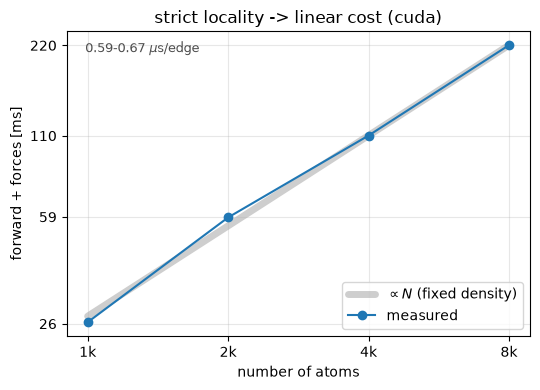

In [18]:
def time_forward(N, rho=0.1, reps=5):
    L = (N / rho) ** (1 / 3)
    pos_t = torch.rand(N, 3, device=device) * L
    spec_t = torch.randint(0, N_SPECIES, (N,), device=device)
    ei_t = radius_graph(pos_t, r_cut)                      # O(N^2), excluded from the timing
    for _ in range(3):                                     # warm-up
        forces(model, pos_t.clone(), ei_t, spec_t)
    if device == "cuda":
        torch.cuda.synchronize()
    samples = []
    for _ in range(5):                                     # median rides out GPU contention
        t0 = time.time()
        for _ in range(reps):
            forces(model, pos_t.clone(), ei_t, spec_t)
        if device == "cuda":
            torch.cuda.synchronize()
        samples.append((time.time() - t0) / reps * 1e3)
    return float(np.median(samples)), ei_t.shape[1]        # ms, edges

# Start past the dispatch-overhead floor (see above); the top end is set by the
# O(N^2) neighbour search and the ~50 edges/atom of this density -- about 4 GiB at
# N = 8192. CPU has a lower floor, so it sweeps a lower range.
Ns = [1024, 2048, 4096, 8192] if device == "cuda" else [256, 512, 1024, 2048]
times, edges = zip(*[time_forward(N) for N in Ns])
for N, t, e in zip(Ns, times, edges):
    print(f"N = {N:6d} | edges = {e:7d} | energy+forces: {t:8.2f} ms"
          f" | {1e3 * t / e:5.2f} us/edge")

fig, ax = plt.subplots(figsize=(5.5, 4))
# Draw the ideal as a wide band so the measurement is visible riding on top of it
per_atom = np.median(np.array(times) / np.array(Ns))    # robust anchor, not one endpoint
ax.loglog(Ns, np.array(Ns) * per_atom, color="0.65", lw=5, alpha=0.55,
          solid_capstyle="round", zorder=1, label=r"$\propto N$ (fixed density)")
ax.loglog(Ns, times, "o-", color="C0", lw=1.5, ms=6, zorder=2, label="measured")
us_per_edge = [1e3 * t / e for t, e in zip(times, edges)]
ax.text(0.04, 0.93, f"{min(us_per_edge):.2f}-{max(us_per_edge):.2f} " + r"$\mu$s/edge",
        transform=ax.transAxes, fontsize=9, color="0.3")
ax.set_xticks(Ns); ax.set_xticklabels([f"{n // 1024}k" for n in Ns])
ax.set_yticks([round(t) for t in times])
ax.set_yticklabels([f"{t:.0f}" for t in times])
ax.minorticks_off()
ax.set_xlabel("number of atoms"); ax.set_ylabel("forward + forces [ms]")
ax.set_title(f"strict locality -> linear cost ({device})")
ax.legend(loc="lower right"); ax.grid(alpha=0.3, which="both")
fig.tight_layout()

## Summary

- We implemented Allegro's full pipeline in ~120 lines of e3nn: the two-body embedding with **species one-hots** (Eqs. (7)–(10)), $N_\text{layer}$ two-track layers (Eqs. (11)–(16)), pairwise readout and aggregation (Eqs. (17), (6), (5)), forces by autograd.
- Verified in float64: energy invariance and force covariance under rotations, inversion, and translations at $\sim 10^{-15}$; the trained float32 model sits at its round-off floor ($\sim 10^{-6}$ eV).
- The envelope $u(r)$ on every pair quantity makes the potential **smooth at the cutoff** — verified with a batched pair scan, where beyond $r_c$ the energy is *exactly* $2\mu$ to the last bit.
- Trained on rMD17 aspirin under Lesson 08c's protocol: **≈62 meV/Å** validation force MAE and ≈1.5 meV/atom, against NequIP's **85.28 meV/Å** and 1.51 meV/atom on the same 150 frames — with 12,171 parameters to NequIP's 70,794 and ≈200 s to its 473 s. (The seed is fixed, but GPU scatter-adds use nondeterministic atomics, so repeated runs land within about 1 meV/Å of each other.) Each model is trained under its own paper's loss, so read this as two published recipes on one dataset rather than a single-variable ablation; still, strict locality is clearly not a concession on this molecule.
- Forward cost grows linearly with atom count at fixed density — the toy-scale echo of the paper's 100-million-atom argument.

**Next:** Lesson 10 — the Atomic Cluster Expansion and MACE, which make the body-order view of these iterated tensor products explicit.

## Exercises

**1. Ablate the tensor track.** Build the model with `l_max=0` (the tensor track carries
only scalars, so the layers reduce to distance-based MLPs) and retrain. How much does
validation force MAE degrade — and why would LJ argon have hidden the effect?

<details><summary>Solution</summary>

```python
torch.manual_seed(0)
model0 = AllegroModel(r_cut=r_cut, n_species=N_SPECIES, avg_n_neighbors=avg_n, l_max=0,
                      energy_shift=0.0, energy_scale=float(F_scale)).to(device)
# ... rerun the optimizer/scheduler of the training cell with model0, then evaluate(model0)
```

```
l_max=0: params  8,283 | E MAE 3.85 meV/atom | F MAE 132 meV/A | ~100 s
l_max=2: params 12,171 | E MAE 1.48 meV/atom | F MAE  62 meV/A | ~200 s
```

Dropping the tensor track costs a factor **2.1 on forces** and 2.5 on energies, bought with
1.5$\times$ the parameters and 2$\times$ the training time. Note the invariant model is not
broken — 132 meV/Å is a working potential — it is simply unable to resolve what the
equivariant features resolve for free.

LJ argon, the shared control of Lessons 07a–08b, **cannot** show this: its energy is a sum of
*pair* terms depending only on $r$, so invariant pair features nearly suffice and the same
ablation barely registers. Aspirin's DFT surface has bond angles, dihedrals, conjugation and
an aromatic ring, so the $\ell \ge 1$ features carry directional information that no
distance-only model can rebuild inside two layers. This is the same contrast the paper reports
on QM9, where a single equivariant layer beat every invariant MPNN (paper Table 3). </details>

**2. Break the cutoff on purpose.** Remove the `* u` factor from the readout line (`E_ij = self.readout(x).squeeze(-1)`) and re-run the pair scan. What happens at $r = r_c$, and why exactly there?

<details><summary>Solution</summary>

The energy jumps discontinuously at $r_c$: for $r < r_c$ the latents vanish ($x \to 0$) but the readout MLP has biases, so $E_{ij} \to \mathrm{MLP}_\text{output}(0) \neq 0$, while for $r \ge r_c$ the pair contributes nothing (in a neighbor-list implementation the edge disappears entirely). The jump equals $\sigma \cdot \mathrm{MLP}_\text{output}(0)$ per ordered pair. Forces near the discontinuity are unusable for MD — energy would not be conserved. This is why *every* pair quantity in Allegro carries the envelope. </details>

**3. Body order.** Our model has $N_\text{layer} = 2$. Following the paper's theoretical analysis (Eqs. (18)–(26)), the equivariant features after $L$ layers contain iterated tensor products $\vec{Y}^{ij} \otimes \vec{Y}^{ik_1} \otimes \cdots \otimes \vec{Y}^{ik_L}$. What body order (number of atoms correlated) do our $V^{ij,2}$ features correspond to, and in what sense are Allegro features "analogous but not equivalent" to ACE basis functions?

<details><summary>Solution</summary>

Each iterated product correlates the central atom $i$, the pair partner $j$, and one neighbor $k_\alpha$ per layer: with $L = 2$ that is $2 + 2 = 4$ atoms, i.e. body order 4 (in general $N_\text{layer} + 2$). The core tensor-product structure matches an ACE expansion of body order $\nu + 1 = N_\text{layer} + 2$ (compare paper Eqs. (23) and (26)) — but Allegro's "radial-chemical weights" $w^{ik,L}$ are *learned functions of all lower-order scalar latents* (Eqs. (27)–(28)) rather than a fixed two-body basis, and nonlinear MLPs make the effective body order formally infinite. Hence: analogous, not equivalent. </details>

## References

- [Musaelian et al., *Learning local equivariant representations for large-scale atomistic dynamics* Nat. Commun. 14 579 (2023)](https://doi.org/10.1038/s41467-023-36329-y)